# Bankruptcy prediction

**Question:** Can we use fewer financial variables and still build a useful decision tree?

We want to help an analyst choose which companies need a closer review.
The target is `Bankrupt?`: 1 means bankruptcy and 0 means no bankruptcy.

Our steps:
1. Load and check the data.
2. Explore the training data and correlations.
3. Select variables with L1 regularization.
4. Compare decision trees and evaluate the final model.

Source: [UCI Taiwanese Bankruptcy Prediction](https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction).
The source describes data collected in Taiwan between 1999 and 2009.

## 1. Imports
Run the cells in order. Keep `data.csv` in the same folder as this notebook. The packages are listed in `requirements.txt`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score, f1_score,
    accuracy_score, ConfusionMatrixDisplay, PrecisionRecallDisplay
)

Matplotlib is building the font cache; this may take a moment.


In [2]:
random_state = 42
plt.rcParams["figure.figsize"] = (8, 4)

## 2. Load and check the data

In [3]:
data = pd.read_csv("data.csv")
data.columns = data.columns.str.strip()
data.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [4]:
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])
data.dtypes.value_counts()

Rows: 6819
Columns: 96


float64    93
int64       3
Name: count, dtype: int64

In [5]:
checks = pd.Series({
    "Missing values": data.isna().sum().sum(),
    "Infinite values": np.isinf(data.to_numpy()).sum(),
    "Duplicate rows": data.duplicated().sum()
})
checks

Missing values     0
Infinite values    0
Duplicate rows     0
dtype: int64

In [6]:
target_counts = data["Bankrupt?"].value_counts().sort_index()
pd.DataFrame({
    "Count": target_counts,
    "Percentage": 100 * target_counts / len(data)
})

,Count,Percentage
Bankrupt?,,
0,6599,96.77372
1,220,3.22628


There are very few bankrupt companies. Accuracy alone can be misleading:
a model that always predicts 0 gets a high accuracy but finds no bankrupt companies.

We use **average precision (AP)** as the main score. It summarizes how well the model
ranks bankrupt companies using precision and recall. Higher is better.
We also report precision, recall, F1 and accuracy.

## 3. Keep a separate test set
We use 80% for training and 20% for testing. `stratify` keeps similar class proportions. From this point, exploration uses the training set. We use the test set only at the end.

In [7]:
X = data.drop(columns="Bankrupt?")
y = data["Bankrupt?"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=random_state
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 5455
Test rows: 1364


## 4. Basic exploration

In [8]:
X_train.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
ROA(C) before interest and depreciation before interest,5455.0,5.044466e-01,6.035418e-02,0.024277,0.476113,5.021206e-01,5.346122e-01,1.000000e+00
ROA(A) before interest and % after tax,5455.0,5.578182e-01,6.535483e-02,0.000000,0.535379,5.593655e-01,5.879579e-01,1.000000e+00
ROA(B) before interest and depreciation after tax,5455.0,5.529461e-01,6.140118e-02,0.033514,0.527143,5.516891e-01,5.827400e-01,1.000000e+00
Operating Gross Margin,5455.0,6.077647e-01,1.704699e-02,0.000000,0.600473,6.059831e-01,6.138169e-01,6.651508e-01
Realized Sales Gross Margin,5455.0,6.077417e-01,1.702754e-02,0.000000,0.600463,6.059182e-01,6.136943e-01,6.660229e-01
Operating Profit Rate,5455.0,9.987807e-01,1.355629e-02,0.000000,0.998969,9.990217e-01,9.990924e-01,1.000000e+00
Pre-tax net Interest Rate,5455.0,7.972549e-01,1.146745e-02,0.000000,0.797386,7.974617e-01,7.975758e-01,1.000000e+00
After-tax net Interest Rate,5455.0,8.091782e-01,1.047954e-02,0.084286,0.809311,8.093743e-01,8.094674e-01,1.000000e+00
Non-industry income and expenditure/revenue,5455.0,3.036832e-01,1.160722e-02,0.062507,0.303467,3.035253e-01,3.035830e-01,1.000000e+00
Continuous interest rate (after tax),5455.0,7.814508e-01,1.109291e-02,0.000000,0.781566,7.816337e-01,7.817311e-01,1.000000e+00


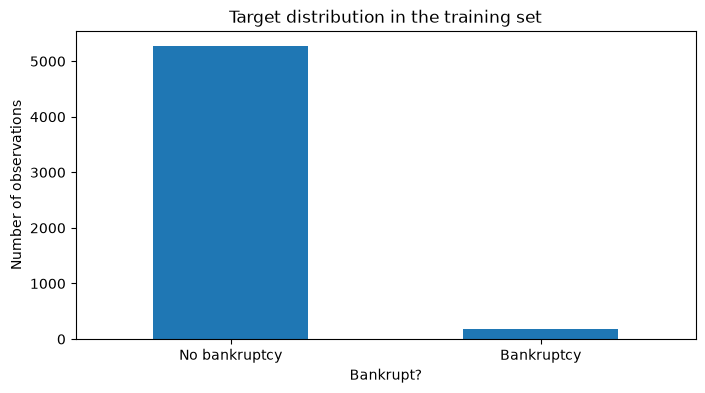

In [9]:
y_train.value_counts().sort_index().plot.bar()
plt.xticks([0, 1], ["No bankruptcy", "Bankruptcy"], rotation=0)
plt.ylabel("Number of observations")
plt.title("Target distribution in the training set")
plt.show()

In [10]:
constant_columns = X_train.columns[X_train.nunique() == 1].tolist()
print("Constant columns:", constant_columns)

Constant columns: ['Net Income Flag']


In [11]:
duplicate_columns = X_train.columns[X_train.T.duplicated()].tolist()
print("Repeated columns:", duplicate_columns)

Repeated columns: ['Current Liability to Liability', 'Current Liability to Equity']


Constant columns contain no information for separating the classes.
Some columns are also exact copies of others. The pipeline removes constant columns.
We leave the other columns available to the selection step.

In [12]:
ranges = pd.DataFrame({
    "Minimum": X_train.min(),
    "Median": X_train.median(),
    "Maximum": X_train.max()
})
ranges.sort_values("Maximum", ascending=False).head(10)

,Minimum,Median,Maximum
Current Asset Turnover Rate,0.0000,1.982660e-04,1.000000e+10
Quick Asset Turnover Rate,0.0000,2.268861e-04,1.000000e+10
Cash Turnover Rate,0.0000,1.140000e+09,1.000000e+10
Inventory Turnover Rate (times),0.0001,7.325740e-04,9.990000e+09
Fixed Assets Turnover Frequency,0.0000,5.862858e-04,9.990000e+09
Operating Expense Rate,0.0000,2.752149e-04,9.990000e+09
Total Asset Growth Rate,0.0000,6.400000e+09,9.980000e+09
Research and development expense rate,0.0000,4.920000e+08,9.980000e+09
Inventory/Current Liability,0.0000,6.522034e-03,9.910000e+09
Total assets to GNP price,0.0000,2.066146e-03,9.820000e+09


Some variables have very large values. We do not assume these are errors or delete them.
Scaling will help the L1 model compare variables on different scales.
A decision tree does not need scaling.

## 5. Correlation
We use Pearson correlation to explore linear relationships. Correlation is not proof of causation and can miss nonlinear patterns. Here it helps us understand the data; it is not a separate selection rule.

In [13]:
train_data = X_train.copy()
train_data["Bankrupt?"] = y_train

correlations = train_data.corr()["Bankrupt?"].drop("Bankrupt?").dropna()
top_names = correlations.abs().sort_values(ascending=False).head(10).index
correlations.loc[top_names].to_frame("Correlation with bankruptcy")

,Correlation with bankruptcy
Net Income to Total Assets,-0.316354
ROA(A) before interest and % after tax,-0.283811
ROA(B) before interest and depreciation after tax,-0.275219
ROA(C) before interest and depreciation before interest,-0.262665
Net worth/Assets,-0.247642
Debt ratio %,0.247642
Persistent EPS in the Last Four Seasons,-0.221009
Retained Earnings to Total Assets,-0.213839
Net Income to Stockholder's Equity,-0.206648
Net profit before tax/Paid-in capital,-0.206277


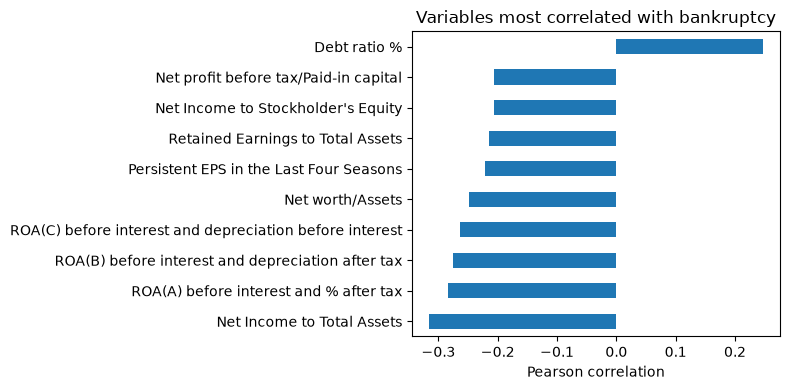

In [14]:
correlations.loc[top_names].sort_values().plot.barh()
plt.xlabel("Pearson correlation")
plt.title("Variables most correlated with bankruptcy")
plt.tight_layout()
plt.show()

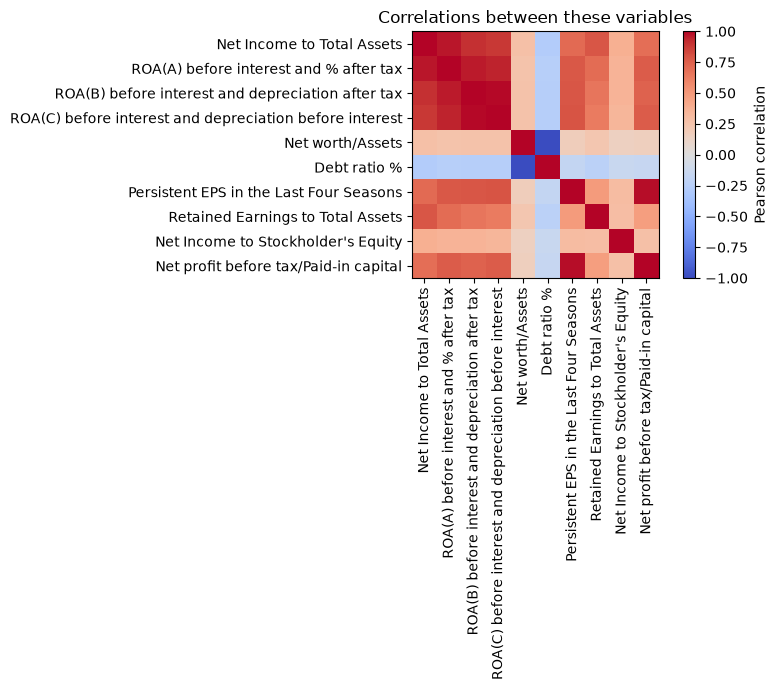

In [15]:
correlation_matrix = X_train[top_names].corr()

plt.figure(figsize=(9, 7))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(top_names)), top_names, rotation=90)
plt.yticks(range(len(top_names)), top_names)
plt.colorbar(label="Pearson correlation")
plt.title("Correlations between these variables")
plt.tight_layout()
plt.show()

Strong correlations between predictors suggest that some variables carry similar information.
This gives us a reason to try variable selection, but it does not guarantee better predictions.

## 6. Validation and model settings

We use 5-fold stratified cross-validation on the training set.
Each pipeline learns its preprocessing and selection only from the training part of each fold.

We try a small number of settings:
- Tree depth: 3 or 5.
- Minimum observations per leaf: 10 or 30.
- `class_weight="balanced"` gives more weight to the rare bankruptcy class.

We choose settings using average precision. The test set is not used for tuning.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

tree_grid = {
    "tree__max_depth": [3, 5],
    "tree__min_samples_leaf": [10, 30]
}

## 7. Decision tree without variable selection
This model is our reference for measuring the value of selection. It only removes constant columns.

In [17]:
tree_pipeline = Pipeline([
    ("constant", VarianceThreshold()),
    ("tree", DecisionTreeClassifier(
        class_weight="balanced", random_state=random_state
    ))
])

In [18]:
tree_search = GridSearchCV(
    tree_pipeline, tree_grid, scoring="average_precision", cv=cv
)
tree_search.fit(X_train, y_train)

print("Best settings:", tree_search.best_params_)
print("Validation AP:", round(tree_search.best_score_, 3))

Best settings: {'tree__max_depth': 5, 'tree__min_samples_leaf': 30}
Validation AP: 0.245


## 8. LASSO-style variable selection

Ordinary LASSO is a regression method. Because our target is binary, we use
**logistic regression with an L1 penalty** instead. This is LASSO-style selection
for classification: some coefficients become zero.

We keep variables with a nonzero coefficient, then train a decision tree on them.
The logistic regression is used for selection; the final classifier is a decision tree.

`C` controls the penalty. A smaller `C` means stronger regularization.
We try 0.01, 0.1 and 1. The scaler and selector are fitted again inside each validation fold.

In [19]:
l1_model = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    class_weight="balanced",
    max_iter=2000,
    random_state=random_state
)

selected_pipeline = Pipeline([
    ("constant", VarianceThreshold()),
    ("scale", StandardScaler()),
    ("selection", SelectFromModel(l1_model, threshold=0.00001)),
    ("tree", DecisionTreeClassifier(
        class_weight="balanced", random_state=random_state
    ))
])

In [20]:
selection_grid = {
    "selection__estimator__C": [0.01, 0.1, 1],
    "tree__max_depth": [3, 5],
    "tree__min_samples_leaf": [10, 30]
}

selection_search = GridSearchCV(
    selected_pipeline, selection_grid, scoring="average_precision", cv=cv
)
selection_search.fit(X_train, y_train)

print("Best settings:", selection_search.best_params_)
print("Validation AP:", round(selection_search.best_score_, 3))

Best settings: {'selection__estimator__C': 0.01, 'tree__max_depth': 5, 'tree__min_samples_leaf': 30}
Validation AP: 0.276


## 9. Selected variables
After choosing settings, `GridSearchCV` fits the best pipeline on the full training set. The following variables come from that fitted pipeline.

In [21]:
selected_model = selection_search.best_estimator_
variable_names = X_train.columns[
    selected_model.named_steps["constant"].get_support()
]
selector = selected_model.named_steps["selection"]
selected_names = variable_names[selector.get_support()]

print("Original variables:", X_train.shape[1])
print("Selected variables:", len(selected_names))

Original variables: 95
Selected variables: 17


In [22]:
coefficients = pd.Series(
    selector.estimator_.coef_[0], index=variable_names
)
selected_coefficients = coefficients.loc[selected_names]
selected_coefficients = selected_coefficients.loc[
    selected_coefficients.abs().sort_values(ascending=False).index
]
selected_coefficients.to_frame("L1 coefficient")

,L1 coefficient
Debt ratio %,0.680481
Persistent EPS in the Last Four Seasons,-0.536444
Net Income to Total Assets,-0.475169
Net worth/Assets,-0.457916
Total Asset Turnover,-0.139826
Cash Turnover Rate,-0.134791
Cash Flow to Liability,-0.109755
Fixed Assets Turnover Frequency,0.101354
ROA(C) before interest and depreciation before interest,-0.098235
Net Worth Turnover Rate (times),-0.079315


These coefficients describe the selection model, not the tree. Correlated variables can replace each other, so the selected list may change with a different training sample.

In [23]:
validation_results = pd.DataFrame({
    "Model": ["Tree without selection", "L1 selection + tree"],
    "Mean validation AP": [
        tree_search.best_score_, selection_search.best_score_
    ],
    "Validation AP standard deviation": [
        tree_search.cv_results_["std_test_score"][tree_search.best_index_],
        selection_search.cv_results_["std_test_score"][selection_search.best_index_]
    ],
    "Variables available to the tree": [
        tree_search.best_estimator_.named_steps["constant"].get_support().sum(),
        len(selected_names)
    ]
})
validation_results.round(3)

,Model,Mean validation AP,Validation AP standard deviation,Variables available to the tree
0,Tree without selection,0.245,0.034,94
1,L1 selection + tree,0.276,0.028,17


## 10. Choose the model before looking at the test results
We recommend the model with the higher mean validation AP. We still report both trees to show whether selection helped.

In [24]:
if selection_search.best_score_ >= tree_search.best_score_:
    final_name = "L1 selection + tree"
    final_model = selection_search.best_estimator_
else:
    final_name = "Tree without selection"
    final_model = tree_search.best_estimator_

print("Model chosen using validation:", final_name)

Model chosen using validation: L1 selection + tree


## 11. Final test results
The baseline always predicts the most common class. Precision, recall and F1 use each model's default class predictions. Average precision uses its probability scores.

In [25]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

models = {
    "Majority baseline": baseline,
    "Tree without selection": tree_search.best_estimator_,
    "L1 selection + tree": selection_search.best_estimator_
}

In [26]:
results = []

for name, model in models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Average precision": average_precision_score(y_test, probability),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "F1": f1_score(y_test, prediction, zero_division=0),
        "Accuracy": accuracy_score(y_test, prediction)
    })

test_results = pd.DataFrame(results).set_index("Model")
test_results.round(3)

,Average precision,Recall,Precision,F1,Accuracy
Model,,,,,
Majority baseline,0.032,0.000,0.000,0.000,0.968
Tree without selection,0.260,0.818,0.185,0.301,0.878
L1 selection + tree,0.271,0.773,0.158,0.263,0.860


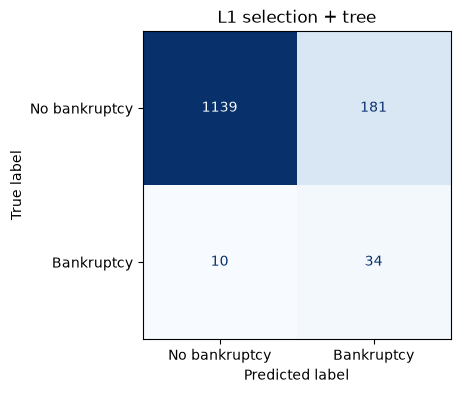

In [27]:
final_prediction = final_model.predict(X_test)
final_probability = final_model.predict_proba(X_test)[:, 1]

ConfusionMatrixDisplay.from_predictions(
    y_test, final_prediction,
    display_labels=["No bankruptcy", "Bankruptcy"],
    cmap="Blues", colorbar=False
)
plt.title(final_name)
plt.show()

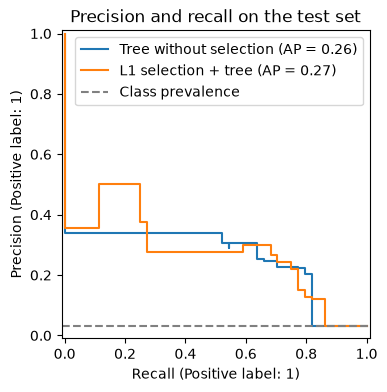

In [28]:
for name in ["Tree without selection", "L1 selection + tree"]:
    probability = models[name].predict_proba(X_test)[:, 1]
    PrecisionRecallDisplay.from_predictions(
        y_test, probability, name=name, ax=plt.gca()
    )

plt.axhline(y_test.mean(), color="gray", linestyle="--", label="Class prevalence")
plt.title("Precision and recall on the test set")
plt.legend()
plt.show()

## 12. Understand the combined model
We show the first three levels of the tree after L1 selection. Some branches may continue below the displayed levels. Thresholds use standardized values because this tree follows the scaler.

Because we use balanced class weights, the `value` proportions in the tree are weighted class proportions, not the original class frequencies.

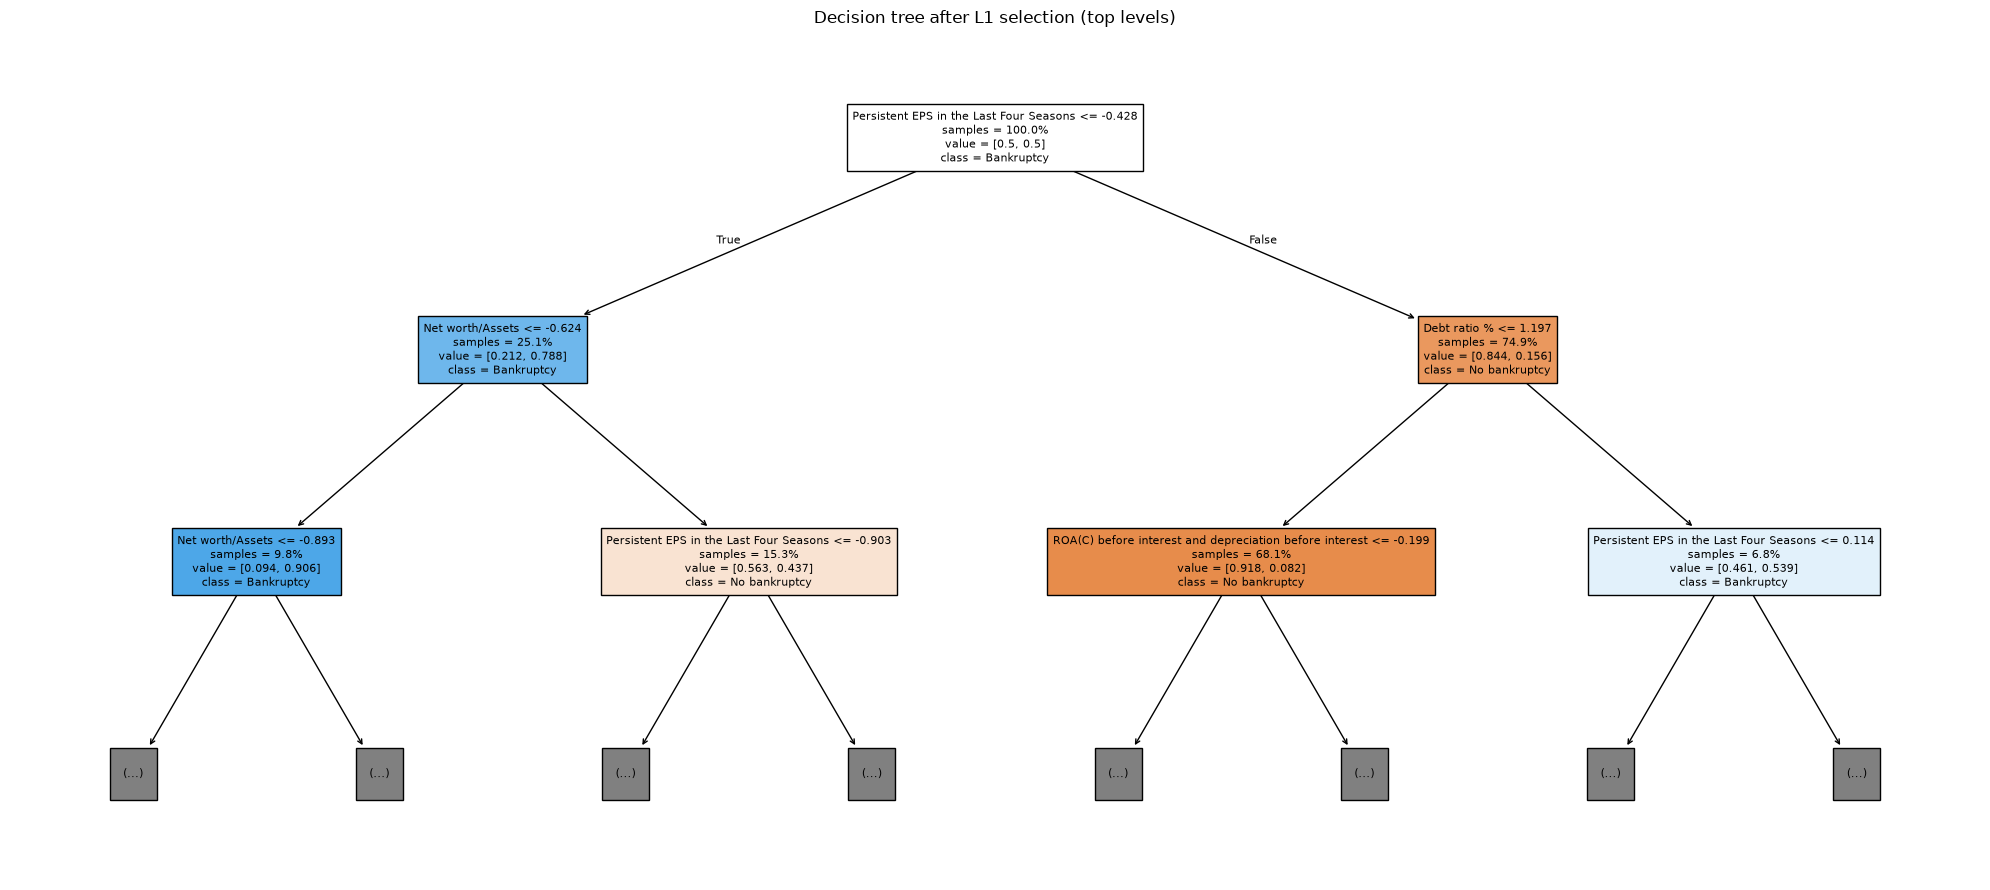

In [29]:
plt.figure(figsize=(20, 9))
plot_tree(
    selected_model.named_steps["tree"],
    feature_names=selected_names.tolist(),
    class_names=["No bankruptcy", "Bankruptcy"],
    max_depth=2,
    filled=True,
    impurity=False,
    proportion=True,
    fontsize=8
)
plt.title("Decision tree after L1 selection (top levels)")
plt.tight_layout()
plt.show()

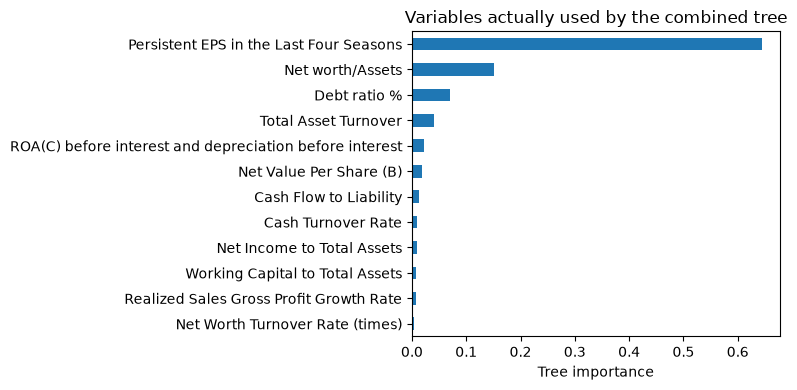

In [30]:
importance = pd.Series(
    selected_model.named_steps["tree"].feature_importances_,
    index=selected_names
)
importance[importance > 0].sort_values().plot.barh()
plt.xlabel("Tree importance")
plt.title("Variables actually used by the combined tree")
plt.tight_layout()
plt.show()

## 13. Conclusion

In [31]:
final_scores = test_results.loc[final_name]
combined_scores = test_results.loc["L1 selection + tree"]
detected = ((y_test == 1) & (final_prediction == 1)).sum()
missed = ((y_test == 1) & (final_prediction == 0)).sum()
false_alarms = ((y_test == 0) & (final_prediction == 1)).sum()

print(f"L1 selection kept {len(selected_names)} of {X_train.shape[1]} variables.")
print(f"Combined model test AP: {combined_scores['Average precision']:.3f}")
print(f"Recommended model, chosen by validation: {final_name}")
print(f"Final test AP: {final_scores['Average precision']:.3f}")
print(f"Final test recall: {final_scores['Recall']:.1%}")
print(f"Final test precision: {final_scores['Precision']:.1%}")
print(f"Bankrupt companies detected: {detected}")
print(f"Bankrupt companies missed: {missed}")
print(f"False alarms: {false_alarms}")

L1 selection kept 17 of 95 variables.
Combined model test AP: 0.271
Recommended model, chosen by validation: L1 selection + tree
Final test AP: 0.271
Final test recall: 77.3%
Final test precision: 15.8%
Bankrupt companies detected: 34
Bankrupt companies missed: 10
False alarms: 181


### What we found in this run

L1 selection kept **17 of 95 variables**. The combined model had a mean validation AP of **0.276**, compared with **0.245** for the tree without selection, so we chose the combined model before checking the test set.

On the test set, its AP was **0.271**, compared with **0.260** for the tree without selection and **0.032** for the majority baseline. It detected **34 of 44** bankrupt companies, missed **10**, and raised **181 false alarms**. Its recall was **77.3%** and its precision was **15.8%**.

Selection reduced the number of variables and slightly improved AP in this run. However, the tree without selection had higher test recall and precision at the default decision threshold. The combined model is therefore not better on every metric, and this small AP difference does not establish a reliable improvement.

### Recommendation and limits

Use the recommended tree as a simple screening tool to help an analyst prioritize reviews.
False alarms create extra work, while missed bankruptcies are cases the model fails to flag.
This experiment does not justify automatic lending decisions.

- There are only 220 bankrupt observations in the full dataset, so scores can vary with the split.
- The data come from Taiwan in 1999–2009. Results may not transfer to other countries or current companies.
- This file has no date or company identifier for a time-based or company-grouped split.
  Our random split does not prove future forecasting performance.
- Correlation and variable importance do not establish causation.
- L1 selection uses a linear model and can miss variables useful through nonlinear interactions.
- We used a small parameter grid to keep the project simple. Selection does not have to improve the score to be worth studying.

### Final report

This notebook supports the **Combined** approach in the brief.
The final submission must still be a compiled PDF report with methods, results, plots,
readable code extracts and limitations.
The brief also requires an appendix containing the full prompts and full LLM answers,
verbatim, for every exchange used in the report.